# Recherche évolutionnaire — fitness par courbes de désirabilité

Chaque propriété passe par une **courbe paramétrable** qui renvoie un score entre **0** (mauvais) et **1** (parfait) :
sigmoïdes montantes / descendantes (combinables dans une même courbe), gaussienne…
Les scores sont ensuite combinés en **somme pondérée** ou **moyenne géométrique**.

Code des courbes : `scripts/Lea/fitness_functions.py`. Le script `evolutionary_algorithm.py` n'est pas modifié :
on remplace seulement sa fonction `_build_fitness` au moment du lancement.

1. Imports — 2. Tests — 3. Paramètres — 4. Réglage des courbes — 5. Callback — 6. Lancement — 7. Résultats — 8. Évolution de la population sur les courbes

In [32]:
import os, sys, io, html, math, tempfile, time, importlib.util
from pathlib import Path

# racine du projet = premier dossier parent qui contient evomol/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "evomol").is_dir())
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)  # les filtres ChEMBL/ZINC lisent external_data/ en relatif

from IPython.display import display, clear_output
import ipywidgets as widgets
import matplotlib.pyplot as plt
from matplotlib import cm, colors as mcolors
from rdkit.Chem import Draw, MolFromSmiles

from evomol import evaluation as ev
from evomol.representation import MolecularGraph
from evomol.search.parameters import search_parameters


def _load(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

ff  = _load("fitness_functions", ROOT / "scripts" / "Lea" / "fitness_functions.py")
_ea = _load("evolutionary_algorithm", ROOT / "scripts" / "Lea" / "evolutionary_algorithm.py")
ps  = _load("parallel_search", ROOT / "scripts" / "Lea" / "parallel_search.py")  # résumé et trajectoire (§ 8)
Sigmoid, Gaussian = ff.Sigmoid, ff.Gaussian


def _fig_png(fig):
    # Figure matplotlib → PNG, affiché dans un widgets.Image
    # (le widget Output ne se charge pas sous VS Code)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=90, bbox_inches="tight")
    plt.close(fig)
    return buf.getvalue()

print("Imports OK")

Imports OK


## 1. Tests

Vérifie les courbes, la combinaison et l'intégration avec l'algorithme, pour repérer ce qui ne marcherait pas.
Chaque test affiche **OK** ou **ÉCHEC** ; un résumé est donné à la fin.

In [33]:
_results = []
_ORIGINAL_BUILD = _ea._build_fitness

def check(name, fn):
    try:
        fn()
        _results.append((name, True, ""))
        print(f"OK     {name}")
    except Exception as e:  # noqa: BLE001
        _results.append((name, False, f"{type(e).__name__}: {e}"))
        print(f"ÉCHEC  {name}  →  {type(e).__name__}: {e}")

def raises(exc, fn, *args, **kwargs):
    try:
        fn(*args, **kwargs)
    except exc:
        return
    raise AssertionError(f"{exc.__name__} attendue, rien n'a été levé")

def close(a, b, tol=1e-9):
    assert abs(a - b) <= tol, f"{a} != {b}"

GRID = [-1e6, -1e3, -10, -1, -0.1, 0, 0.1, 0.5, 1, 10, 1e3, 1e6, math.inf, -math.inf]
CURVES = [
    Sigmoid(0.5, 10, "up"), Sigmoid(0.5, 10, "down"), Sigmoid(0, 1e6, "up"),
    Gaussian(0.3, 0.1), Gaussian(0, 1e-6),
    Sigmoid(0.2, 30, "up") * Sigmoid(0.6, 30, "down"),
    Sigmoid(0, 5, "up") * Gaussian(1, 2) * Sigmoid(3, 5, "down"),
]

# ── Courbes ────────────────────────────────────────────────────────────────
def t_bornes():
    for c in CURVES:
        for x in GRID:
            s = c(x)
            assert 0.0 <= s <= 1.0 and not math.isnan(s), f"{c!r}({x}) = {s}"
check("bornes [0,1] sur grille large, ±inf, raideur extrême (pas d'overflow)", t_bornes)

def t_sigmoid():
    up, down = Sigmoid(2, 3, "up"), Sigmoid(2, 3, "down")
    close(up(2), 0.5); close(down(2), 0.5)
    xs = [i / 10 for i in range(-50, 90)]
    assert all(up(a) <= up(b) for a, b in zip(xs, xs[1:])), "up non croissante"
    assert all(down(a) >= down(b) for a, b in zip(xs, xs[1:])), "down non décroissante"
    close(up(1e9), 1.0); close(down(1e9), 0.0)
    for x in xs:
        close(up(x) + down(x), 1.0, 1e-12)
check("sigmoïde : 0.5 au centre, monotone, up + down = 1", t_sigmoid)

def t_gaussian():
    g = Gaussian(0.4, 0.2)
    close(g(0.4), 1.0)
    for d in (0.05, 0.2, 1.0):
        close(g(0.4 + d), g(0.4 - d), 1e-12)
    close(g(0.6), math.exp(-0.5))
check("gaussienne : 1 au centre, symétrique, exp(-1/2) à 1 σ", t_gaussian)

def t_fenetre():
    w = Sigmoid(0.2, 60, "up") * Sigmoid(0.6, 60, "down")
    assert w(0.4) > 0.99, w(0.4)
    assert w(0.0) < 0.01 and w(0.8) < 0.01, (w(0.0), w(0.8))
    assert len(w.leaves()) == 2
    w3 = w * Gaussian(0.4, 1)
    assert len(w3.leaves()) == 3, "le produit doit s'aplatir"
    close(w3(0.4), w(0.4) * Gaussian(0.4, 1)(0.4))
check("produit montante × descendante = fenêtre ; produit de 3 courbes", t_fenetre)

def t_invalides():
    raises(ValueError, Sigmoid, 0, 0)
    raises(ValueError, Sigmoid, 0, -1)
    raises(ValueError, Sigmoid, 0, 1, "haut")
    raises(ValueError, Sigmoid, math.nan, 1)
    raises(ValueError, Gaussian, 0, 0)
    raises(ValueError, Gaussian, 0, -0.1)
    raises(ValueError, ff.Product)
    raises(TypeError, ff.Product, Sigmoid(0, 1), 3)
    raises(ValueError, Sigmoid(0, 1), math.nan)
    raises(TypeError, Sigmoid(0, 1), None)
    raises(TypeError, Sigmoid(0, 1), "abc")
check("paramètres invalides et valeurs NaN / non numériques → erreur", t_invalides)

def t_set_param():
    s = Sigmoid(0, 1)
    s.set_param("center", 2.5); close(s.center, 2.5)
    raises(ValueError, s.set_param, "steepness", -3)
    close(s.steepness, 1.0)  # l'ancienne valeur est conservée
    raises(KeyError, s.set_param, "sigma", 1)
    c = s.copy(); c.set_param("center", 9); close(s.center, 2.5)
check("set_param : validation, rollback, copie indépendante", t_set_param)

def t_repr():
    for c in CURVES:
        again = eval(repr(c), {"Sigmoid": Sigmoid, "Gaussian": Gaussian})
        for x in (-1, 0, 0.3, 2):
            close(again(x), c(x), 1e-6)
check("repr recopiable : eval(repr(courbe)) redonne la même courbe", t_repr)

# ── Combinaison ────────────────────────────────────────────────────────────
def t_aggregate():
    import random
    rng = random.Random(0)
    for _ in range(500):
        n = rng.randint(1, 5)
        s = [rng.random() for _ in range(n)]
        w = [rng.choice([0, rng.random() * 5]) for _ in range(n)]
        if sum(w) == 0:
            w[0] = 1
        for mode in ff.AGGREGATIONS:
            f = ff.aggregate(s, w, mode)
            assert 0 <= f <= 1, (s, w, mode, f)
    close(ff.aggregate([0.2, 0.8], [1, 1], "sum"), 0.5)
    close(ff.aggregate([0.25, 1.0], [1, 1], "geometric"), 0.5)
    close(ff.aggregate([0.0, 1.0], [1, 1], "geometric"), 0.0)
    close(ff.aggregate([0.0, 0.7], [0, 1], "geometric"), 0.7)   # poids 0 ignoré
    close(ff.aggregate([0.3, 0.7], [2, 0], "sum"), 0.3)
check("aggregate : bornes, valeurs connues, score 0 en géométrique, poids 0", t_aggregate)

def t_aggregate_err():
    raises(ValueError, ff.aggregate, [0.5], [0], "sum")
    raises(ValueError, ff.aggregate, [0.5], [-1], "sum")
    raises(ValueError, ff.aggregate, [0.5], [math.nan], "sum")
    raises(ValueError, ff.aggregate, [0.5], [1], "produit")
    raises(ValueError, ff.aggregate, [0.5, 0.5], [1], "sum")
check("aggregate : Σ poids = 0, poids négatif/NaN, mode inconnu → erreur", t_aggregate_err)

# ── Fitness sur des molécules ──────────────────────────────────────────────
class FakeMol:
    def __init__(self, **values):
        self._v = values
    def value(self, name):
        return self._v[name]

def t_build_fake():
    goals = [("a", Sigmoid(0, 10, "up"), 1.0), ("b", Gaussian(5, 1), 3.0)]
    f = ff.build_fitness(goals, "sum")
    close(f._evaluate(FakeMol(a=100, b=5)), 1.0)
    close(f._evaluate(FakeMol(a=-100, b=5)), 0.75)
    g = ff.build_fitness(goals, "geometric")
    close(g._evaluate(FakeMol(a=-100, b=5)), 0.0, 1e-6)
    assert f.name == "fitness"
check("build_fitness sur fausse molécule (sum / geometric)", t_build_fake)

def t_build_nan():
    f = ff.build_fitness([("a", Sigmoid(0, 1), 1.0)])
    raises(ev.EvaluationError, f._evaluate, FakeMol(a=math.nan))
check("propriété NaN → EvaluationError (molécule rejetée, la recherche continue)", t_build_nan)

def t_check_goals():
    raises(ValueError, ff.check_goals, [])
    raises(ValueError, ff.check_goals, [("huckel_homo_lambda", "min", 1.0, None)])  # ancien format
    raises(TypeError, ff.check_goals, [("a", "min", 1.0)])
    raises(TypeError, ff.check_goals, [(3, Sigmoid(0, 1), 1.0)])
    raises(ValueError, ff.check_goals, [("a", Sigmoid(0, 1), 0.0)])
    raises(ValueError, ff.check_goals, [("a", Sigmoid(0, 1), 1.0)], "max")
check("check_goals : vide, ancien format, courbe/nom invalide, poids nul, agrégation inconnue", t_check_goals)

def t_unknown_name():
    f = ff.build_fitness([("propriete_inexistante", Sigmoid(0, 1), 1.0)])
    raises(KeyError, f._evaluate, FakeMol(a=1))
check("nom de propriété inconnu → KeyError (contrôlé avant lancement, voir § Lancement)", t_unknown_name)

def t_vraie_molecule():
    from evomol import default_parameters as dp
    from evomol.representation import Molecule
    dp.setup_default_parameters(accepted_atoms=["C", "N", "O"], max_heavy_atoms=38)
    goals = [("huckel_homo_lambda", Sigmoid(0.5, 15, "down"), 1.0),
             ("SAScore", Sigmoid(4, 2, "down"), 1.0)]
    chain = [ev.Huckel(), ev.HuckelHOMO(), ev.SAScore, ff.build_fitness(goals, "geometric")]
    m = Molecule("c1ccccc1")
    for e in chain:
        e.evaluate(m)
    fit = m.value("fitness")
    assert 0 <= fit <= 1, fit
    details = ff.goal_scores(m, goals)
    expected = ff.aggregate([s for *_, s in details], [1, 1], "geometric")
    close(fit, expected)
    print("         benzène :", ", ".join(f"{n}={v:.3f} (score {s:.3f})" for n, v, s in details),
          f"→ fitness {fit:.4f}")
check("vraie molécule (benzène) avec la chaîne Hückel", t_vraie_molecule)

# ── Intégration : courtes recherches réelles ───────────────────────────────
def _mini_run(aggregation):
    goals = [("huckel_homo_lambda", Sigmoid(0.5, 15, "down"), 1.0),
             ("SAScore", Sigmoid(4, 2, "down"), 1.0)]
    original = _ea._build_fitness
    _ea._build_fitness = lambda g: ff.build_fitness(g, aggregation)
    try:
        evo = _ea.main(
            start_smiles="c1ccccc1", accepted_atoms=["C", "N", "O"], max_heavy_atoms=20,
            huckel=True, max_sp3=None, realism=None, fitness_goals=goals,
            max_generations=30, max_time=8, population_size=15, nb_replacements=5,
            random_seed=0, output_dir=tempfile.mkdtemp(prefix="evomol_test_"),
            save_n_generations=0, save_final_population=False,
        )
    finally:
        _ea._build_fitness = original
    fits = [m.value("fitness") for m in evo.population]
    assert fits, "population vide"
    assert all(0 <= f <= 1 for f in fits), fits
    for m in evo.population:
        close(m.value("fitness"), ff.aggregate([s for *_, s in ff.goal_scores(m, goals)], [1, 1], aggregation))
    print(f"         {aggregation} : {evo.nb_generations} générations, "
          f"{len(fits)} molécules, fitness max {max(fits):.4f}")

check("mini-recherche réelle, aggregation='sum'", lambda: _mini_run("sum"))
check("mini-recherche réelle, aggregation='geometric'", lambda: _mini_run("geometric"))
def t_restore():
    assert _ea._build_fitness is _ORIGINAL_BUILD, "_build_fitness non restauré"
check("_build_fitness d'origine restauré après les tests", t_restore)

# ── Résumé ─────────────────────────────────────────────────────────────────
_fails = [r for r in _results if not r[1]]
print(f"\n{len(_results) - len(_fails)}/{len(_results)} tests OK")
for name, _, err in _fails:
    print(f"  ÉCHEC : {name}\n          {err}")

OK     bornes [0,1] sur grille large, ±inf, raideur extrême (pas d'overflow)
OK     sigmoïde : 0.5 au centre, monotone, up + down = 1
OK     gaussienne : 1 au centre, symétrique, exp(-1/2) à 1 σ
OK     produit montante × descendante = fenêtre ; produit de 3 courbes
OK     paramètres invalides et valeurs NaN / non numériques → erreur
OK     set_param : validation, rollback, copie indépendante
OK     repr recopiable : eval(repr(courbe)) redonne la même courbe
OK     aggregate : bornes, valeurs connues, score 0 en géométrique, poids 0
OK     aggregate : Σ poids = 0, poids négatif/NaN, mode inconnu → erreur
OK     build_fitness sur fausse molécule (sum / geometric)
OK     propriété NaN → EvaluationError (molécule rejetée, la recherche continue)
OK     check_goals : vide, ancien format, courbe/nom invalide, poids nul, agrégation inconnue
OK     nom de propriété inconnu → KeyError (contrôlé avant lancement, voir § Lancement)
         benzène : huckel_homo_lambda=1.000 (score 0.001), SAScore=

## 2. Paramètres de l'expérience

In [34]:
# ── Molécule de départ et espace chimique ───────────────────────────────────
SMILES_DEPART = "c1ccccc1"                   # benzène (possède des électrons π)
#   SMILES quelconque : molécule d'où part la recherche (doit passer les filtres).
ACCEPTED_ATOMS  = ["C"]
#   éléments autorisés dans les molécules générées.
MAX_HEAVY_ATOMS = 38
#   entier >= 1 : nb max d'atomes lourds (hors hydrogènes).
UNIQUE_KEKULE   = False
#   False : SMILES kékulé tel que produit par la mutation (une molécule aromatique peut avoir
#           deux SMILES ; défaut, le plus rapide).
#   True  : un seul SMILES par molécule (plus de doublons, ~15–30 % de candidats/s en moins).

# ── Arrêt de la recherche ───────────────────────────────────────────────────
MAX_GENERATIONS = 10_000_000
MAX_TIME_SEC    = 600       # durée max en secondes

# ── Population et sélection ─────────────────────────────────────────────────
POPULATION_SIZE = 1000
#   entier >= 1 : nb de molécules gardées. Si > 1, la population part de SMILES_DEPART
#   seule et se remplit au fil des générations (cases vides remplies en premier).
NB_REPLACEMENTS = 100
#   entier, 1 <= NB_REPLACEMENTS <= POPULATION_SIZE : nb de pires molécules remplacées par génération.
SELECTION       = "roulette"
#   ordre dans lequel les molécules sont choisies pour être mutées :
#   "best"     : de la meilleure à la pire.
#   "random"   : ordre aléatoire.
#   "roulette" : tirage pondéré par la fitness.
SEED            = 42
#   entier : recherche reproductible (même entier -> même recherche).
#   None   : recherche différente à chaque exécution.

# ── Parallélisation ─────────────────────────────────────────────────────────
N_WORKERS       = 7
#   1          : algorithme d'origine, sur un seul cœur (pas de parallélisation).
#   entier > 1 : nb de cœurs qui cherchent en même temps les remplacements d'une génération
#                (une seule population ; tabou et SMILES invalides partagés entre les cœurs).
#                Résultat reproductible avec SEED quel que soit N_WORKERS, mais différent de N_WORKERS = 1.
#                NB_REPLACEMENTS multiple de N_WORKERS : aucun cœur n'attend.

# ── Mutation ────────────────────────────────────────────────────────────────
DEPTH                = 2
#   entier >= 1 : nb (max) d'actions appliquées à la suite dans une mutation.
RANDOM_DEPTH         = True
#   True  : nb d'actions tiré entre 1 et DEPTH à chaque mutation.
#   False : exactement DEPTH actions.
NB_MAX_TRIES         = 50
#   entier >= 1 : nb de mutants essayés par parent avant de passer au parent suivant.
UNIFORM_OVER_ACTIONS = True
#   False : on tire d'abord un type d'action, puis une action de ce type (types équiprobables).
#   True  : tirage uniforme sur toutes les actions possibles (types avec beaucoup
#           d'actions, ex. ChangeBondMG / MoveGroupMG, tirés plus souvent). Ignore PRESELECT_ACTIONS.
PRESELECT_ACTIONS    = True
#   True  : ne liste que les actions du type tiré (rapide).
#   False : liste toutes les actions avant de tirer (même loi, plus lent).
REMEMBER_INVALID     = True
#   True  : les SMILES déjà jugés invalides ne sont pas réévalués (même recherche, plus rapide).
#   False : chaque candidat est réévalué.

# ── Espace d'action ─────────────────────────────────────────────────────────
INSERT_CARBON       = True
#   True  : InsertCarbonMG disponible. Le C inséré est un sp3 non terminal :
#           il est toujours rejeté par le filtre Hückel.
#   False : InsertCarbonMG retiré.
AVOID_SP3_ON_SP3    = True
#   True  : AddAtomMG ne greffe pas de C sp3 sur un C sp3 (molécules que Hückel rejetterait).
#   False : pas de restriction.
ADD_ATOM_MULTIPLE_BONDS = True
#   True  : AddAtomMG peut aussi greffer le nouvel atome par une double ou triple liaison
#           (=CH2, =O, #N…) quand les valences le permettent. Le nouvel atome n'est alors
#           pas sp3 : permet d'allonger le système π même quand MAX_SP3 est atteint.
#   False : liaison simple uniquement.
AVOID_BOND_BREAKING = False
#   True  : ChangeBondMG ne supprime jamais de liaison (les cycles ne s'ouvrent plus par ChangeBondMG).
#   False : les liaisons de cycle peuvent être ouvertes.
AVOID_BOND_FORMING  = False
#   True  : ChangeBondMG ne crée jamais de liaison entre deux atomes non liés (les cycles ne se ferment plus).
#   False : pas de restriction.
WITH_ADD_GROUP      = False
#   True  : ajoute AddGroupMG (greffe thiophène, benzène, nitro, azide, acide sulfonique).
WITH_REMOVE_GROUP   = False
#   True  : ajoute RemoveGroupMG (retire un groupe d'atomes).

# ── Filtres ── appliqués dans cet ordre : Hückel → sp3 → ChEMBL/ZINC → Hetero
FILTER_HUCKEL  = True
#   True / False : compatibilité Hückel (HuckelCompatible) : tout C sp3 doit être en bout de chaîne.
MAX_SP3        = None
#   None        : filtre inactif.
#   entier >= 0 : nb max d'atomes sans liaison π, tous éléments confondus (FilterSP3).
FILTER_REALISM = "chembl_zinc"
#   "chembl_zinc" : filtres GCF + ECFP sur la base ChEMBL + ZINC (la plus large).
#   "chembl"      : filtres GCF + ECFP sur la base ChEMBL seule (plus restrictif).
#   None          : aucun filtre de réalisme (ni GCF ni ECFP).
MAX_RING_N     = 3
#   entier >= 0 : nb max d'azotes en position de cycle (3 : triazoles OK, tétrazoles rejetés).
#   Ignoré si FILTER_HETERO = False.
FILTER_HETERO  = False
#   True / False : chaînes d'hétéroatomes (HeteroatomChainFilter) : pas 3 hétéroatomes
#   consécutifs hors cycle, pas de O-O-O, au plus MAX_RING_N azotes en cycle.

# ── Orbitales observées ── sélecteur : "HOMO", "LUMO", "HOMO-1", "LUMO+2", … ou indice entier
#   de HOMO-2 à LUMO+2 seulement : le benzène de départ n'a que 6 orbitales π.
ORBITAL_LAMBDAS = ["HOMO-2", "HOMO-1", "HOMO", "LUMO", "LUMO+1", "LUMO+2"]
LAMBDA_OVERLAPS = [("HOMO", "LUMO"), ("HOMO-1", "LUMO"), ("HOMO", "LUMO+1"), ("HOMO-1", "LUMO+1")]
#   2 orbitales ou plus : recouvrement spatial Σᵢ ∏ⱼ |cⱼᵢ| (ignore le signe).
#   leur recouvrement dépend de la base choisie par le calcul.
ORBITAL_LAMBDA_NAMES = [ev.HuckelOrbitalLambda(o).name for o in ORBITAL_LAMBDAS]
LAMBDA_OVERLAP_NAMES = [ev.HuckelOrbitalLambdaOverlap(list(s)).name for s in LAMBDA_OVERLAPS]

# ── Objectifs de fitness : (nom_propriété, courbe, poids) ─────────────────────
# Courbes (score toujours entre 0 et 1) :
#   Sigmoid(center, steepness, "up")    : 0 avant center → 1 après    (≈ maximiser)
#   Sigmoid(center, steepness, "down")  : 1 avant center → 0 après    (≈ minimiser)
#       steepness > 0 : raideur ; largeur de la transition ≈ 4 / steepness
#   Gaussian(center, sigma)             : 1 en center, décroît des deux côtés (≈ cible)
#   courbe_a * courbe_b * …             : plusieurs courbes dans une même courbe
#       ex. Sigmoid(0.2, 30, "up") * Sigmoid(0.6, 30, "down") = fenêtre entre 0.2 et 0.6
fitness_goals = [
    # ("huckel_homo_lambda", Sigmoid(center=0.5, steepness=15, direction="down"), 1.0),  # HOMO λ petit = HOMO haute
    # ("SAScore",            Sigmoid(center=4.0, steepness=2,  direction="down"), 1.0),  # facile à synthétiser
    # ("huckel_gap_lambda",  Sigmoid(center=1.0, steepness=10, direction="down"), 1.0),  # petit gap
    # ("huckel_lumo_lambda", Gaussian(center=0.2, sigma=0.1), 1.0),                       # LUMO λ proche de 0.2
    # ("huckel_gap_lambda",  Sigmoid(0.6, 30, "up") * Sigmoid(1.2, 30, "down"), 1.0),     # gap entre 0.6 et 1.2
    # (LAMBDA_OVERLAP_NAME,  Sigmoid(center=1.0, steepness=5, direction="up"), 1.0),     # overlap HOMO×LUMO grand
    # (ORBITAL_LAMBDA_NAME,  Sigmoid(center=1.0, steepness=10, direction="down"), 1.0),  # λ de ORBITAL_LAMBDA
    # ── Autres propriétés (hors Hückel) ──
    # ("n_heavy_atoms",     Gaussian(center=20, sigma=4), 1.0),                          # ~20 atomes lourds
    # ("mol_weight",        Sigmoid(center=500, steepness=0.05, direction="down"), 1.0), # masse < ~500 g/mol
    # ("QED",               Sigmoid(center=0.5, steepness=10, direction="up"), 1.0),     # drug-likeness 0 → 1
    # ("logP",              Gaussian(center=2.5, sigma=1.5), 1.0),                       # lipophilie modérée
    # ("CycleScore",        Sigmoid(center=-0.5, steepness=5, direction="up"), 1.0),     # 0 si cycles ≤ 6
    # ("PLogP",             Sigmoid(center=0.0, steepness=1, direction="up"), 1.0),
]
# Cible : c4ccc(c3cc(c1ccccc1)c2ccccc2c3)cc4 (22 atomes lourds, C seuls ; passe Hückel + ChEMBL/ZINC).
# Valeurs calculées par ff.reference_values(cible, ORBITAL_LAMBDAS, LAMBDA_OVERLAPS).
# HOMO-2 (λ = +1) et LUMO+2 (λ = −1) sont triplement dégénérées chez la cible : leurs λ servent de cibles,
# mais pas leurs recouvrements (dépendent de la base) → LAMBDA_OVERLAPS n'utilise que HOMO-1 à LUMO+1.
fitness_goals = [
    ('n_heavy_atoms', Gaussian(center=22, sigma=3), 0.5),
    ('huckel_orbital_lambda_HOMO-2', Gaussian(center=1.0, sigma=0.1), 1),        # dégénérée (×3)
    ('huckel_orbital_lambda_HOMO-1', Gaussian(center=0.774443, sigma=0.1), 1),
    ('huckel_orbital_lambda_HOMO', Gaussian(center=0.498195, sigma=0.1), 2),
    ('huckel_orbital_lambda_LUMO', Gaussian(center=-0.498195, sigma=0.1), 2),
    ('huckel_orbital_lambda_LUMO+1', Gaussian(center=-0.774443, sigma=0.1), 1),
    ('huckel_orbital_lambda_LUMO+2', Gaussian(center=-1.0, sigma=0.1), 1),       # dégénérée (×3)
    ('huckel_lambda_HOMO_LUMO', Gaussian(center=1.0, sigma=0.05), 1),
    ('huckel_lambda_HOMO-1_LUMO', Gaussian(center=0.675006, sigma=0.05), 1),
    ('huckel_lambda_HOMO_LUMO+1', Gaussian(center=0.675006, sigma=0.05), 1),
    ('huckel_lambda_HOMO-1_LUMO+1', Gaussian(center=1.0, sigma=0.05), 1),
]

AGGREGATION = "sum"
#   "sum"       : Σ poids·score / Σ poids  (un objectif raté n'annule pas tout)
#   "geometric" : ∏ score^(poids/Σ poids)  (un seul score à 0 → fitness 0 : tous les objectifs doivent être atteints)

# Intervalle de valeurs brutes affiché pour chaque propriété (tracés et curseurs).
# Propriété absente → intervalle déduit des paramètres de la courbe.
CURVE_RANGES = {
    "huckel_homo_lambda": (0.0, 4.0),
    "huckel_lumo_lambda": (-4, 0.5),
    "huckel_gap_lambda":  (0.0, 6.0),
    "SAScore":            (1.0, 10.0),
    "QED":                (0.0, 1.0),
    "n_heavy_atoms":      (0, MAX_HEAVY_ATOMS),
    "mol_weight":         (0, 700),
    "logP":               (-5, 10),
    "CycleScore":         (-10, 0),
}

# ── Sauvegarde ──────────────────────────────────────────────────────────────
OUTPUT_DIR            = None
#   None : output/huckel_homo/ à la racine du projet ; sinon chemin d'un dossier.
SAVE_N_GENERATIONS    = 50
#   entier >= 0 : sauver la population toutes les N générations (0 : jamais).
SAVE_FINAL_POPULATION = True
#   True / False : sauver la population finale.

# ── Affichage ───────────────────────────────────────────────────────────────
TOP_N             = 30      # nombre de meilleures molécules à afficher
AFFICHER_TOUTES   = 50      # redessiner la grille toutes les N générations
HISTORIQUE_TOUTES = 10      # enregistrer la population toutes les N générations (évolution sur les courbes)

ff.check_goals(fitness_goals, AGGREGATION)
print(f"Départ      : {SMILES_DEPART}")
print(f"Durée       : {MAX_TIME_SEC}s  max {MAX_GENERATIONS} générations")
print(f"Agrégation  : {AGGREGATION}")
for name, curve, w in fitness_goals:
    print(f"  {name:<22} poids {w:<4g} {curve!r}")

Départ      : c1ccccc1
Durée       : 600s  max 10000000 générations
Agrégation  : sum
  n_heavy_atoms          poids 0.5  Gaussian(center=22, sigma=3)
  huckel_orbital_lambda_HOMO-2 poids 1    Gaussian(center=1, sigma=0.1)
  huckel_orbital_lambda_HOMO-1 poids 1    Gaussian(center=0.774443, sigma=0.1)
  huckel_orbital_lambda_HOMO poids 2    Gaussian(center=0.498195, sigma=0.1)
  huckel_orbital_lambda_LUMO poids 2    Gaussian(center=-0.498195, sigma=0.1)
  huckel_orbital_lambda_LUMO+1 poids 1    Gaussian(center=-0.774443, sigma=0.1)
  huckel_orbital_lambda_LUMO+2 poids 1    Gaussian(center=-1, sigma=0.1)
  huckel_lambda_HOMO_LUMO poids 1    Gaussian(center=1, sigma=0.05)
  huckel_lambda_HOMO-1_LUMO poids 1    Gaussian(center=0.675006, sigma=0.05)
  huckel_lambda_HOMO_LUMO+1 poids 1    Gaussian(center=0.675006, sigma=0.05)
  huckel_lambda_HOMO-1_LUMO+1 poids 1    Gaussian(center=1, sigma=0.05)


## 3. Réglage des courbes

Curseurs pour chaque paramètre de chaque morceau de courbe et pour le poids ; le tracé se met à jour en direct.
**Appliquer** remplace `fitness_goals` par les courbes réglées et affiche le code à recopier dans la cellule des paramètres
(sinon les réglages sont perdus si on ré-exécute cette cellule).

In [35]:
def _slider(leaf, idx, param, value, xmin, xmax):
    span = (xmax - xmin) or 1.0
    label = f"{type(leaf).__name__} {idx} · {param}"
    style = {"description_width": "170px"}
    layout = widgets.Layout(width="520px")
    if param == "center":
        return widgets.FloatSlider(value=value, min=min(xmin, value), max=max(xmax, value),
                                   step=span / 400, readout_format=".4g",
                                   description=label, style=style, layout=layout,
                                   continuous_update=True)
    if param == "steepness":  # largeur de transition ≈ 4/k : de span/200 à 2·span
        lo, hi = math.log10(2 / span), math.log10(800 / span)
    elif param == "sigma":
        lo, hi = math.log10(span / 500), math.log10(2 * span)
    else:  # paramètre d'une future courbe : saisie libre
        return widgets.FloatText(value=value, description=label, style=style, layout=layout)
    lv = math.log10(value)
    return widgets.FloatLogSlider(value=value, base=10, min=min(lo, lv), max=max(hi, lv),
                                  step=0.01, readout_format=".4g", description=label,
                                  style=style, layout=layout)


def editeur_courbes(goals, ranges):
    draft = [[name, curve.copy(), w] for name, curve, w in goals]
    plot = widgets.Image(format="png")
    text = widgets.HTML()
    message = widgets.HTML()

    def redraw(*_):
        fig, _ = ff.plot_curves([tuple(g) for g in draft], ranges)
        plot.value = _fig_png(fig)
        text.value = "<pre>" + html.escape("\n".join(
            f"{name:<22} poids {w:<5g} {curve!r}" for name, curve, w in draft)) + "</pre>"

    def on_param(leaf, param):
        def handler(change):
            try:
                leaf.set_param(param, change["new"])
                message.value = ""
            except ValueError as e:
                message.value = f"<span style='color:#c00'>{e}</span>"
            redraw()
        return handler

    boxes = []
    for g in draft:
        name, curve, w = g
        xmin, xmax = ranges.get(name) or ff.auto_range(curve)
        rows = [widgets.HTML(f"<b>{name}</b>")]
        wsl = widgets.FloatSlider(value=w, min=0, max=max(5.0, 2 * w), step=0.1,
                                  description="poids", style={"description_width": "170px"},
                                  layout=widgets.Layout(width="520px"))
        def on_weight(change, g=g):
            g[2] = change["new"]
            redraw()
        wsl.observe(on_weight, names="value")
        rows.append(wsl)
        for i, leaf in enumerate(curve.leaves()):
            for param, value in leaf.params().items():
                s = _slider(leaf, i, param, value, xmin, xmax)
                s.observe(on_param(leaf, param), names="value")
                rows.append(s)
            if isinstance(leaf, Sigmoid):
                rows.append(widgets.HTML(f"&nbsp;&nbsp;&nbsp;Sigmoid {i} · direction = {leaf.direction!r}"))
        boxes.append(widgets.VBox(rows))

    apply_btn = widgets.Button(description="Appliquer", button_style="primary")
    def on_apply(_):
        global fitness_goals
        new_goals = [(name, curve.copy(), w) for name, curve, w in draft]
        try:
            ff.check_goals(new_goals, AGGREGATION)
        except (ValueError, TypeError) as e:
            message.value = f"<span style='color:#c00'>{e}</span>"
            return
        fitness_goals = new_goals
        code = "fitness_goals = [\n" + "".join(
            f"    ({name!r}, {curve!r}, {w:g}),\n" for name, curve, w in new_goals) + "]"
        message.value = ("<b>fitness_goals mis à jour.</b> Code à recopier dans les paramètres :"
                         f"<pre>{html.escape(code)}</pre>")
    apply_btn.on_click(on_apply)

    display(widgets.VBox([
        widgets.HBox(boxes, layout=widgets.Layout(flex_flow="row wrap")),
        plot, text, apply_btn, message,
    ]))
    redraw()


editeur_courbes(fitness_goals, CURVE_RANGES)

## 4. Callback de visualisation

In [36]:
def afficher_top(population, generation):
    # Enregistre la population (pour § 7) et met à jour best_seen.
    # Pas d'affichage de molécules ici : le top est affiché en § 6 (Résultats finaux).
    history[generation] = {name: [mol.value(name) for mol in population]
                           for name, *_ in fitness_goals}
    history[generation]["fitness"] = [mol.value(search_parameters.fitness_criteria) for mol in population]
    trajectory.append(ps.trajectory_point(population, generation, time.perf_counter() - _t0))

    for mol in population:
        smiles  = mol.get_representation(MolecularGraph).canonical_smiles
        fitness = mol.value(search_parameters.fitness_criteria)
        if smiles not in best_seen or fitness > best_seen[smiles][0]:
            best_seen[smiles] = (fitness, mol)

    if generation - _last_draw[0] < AFFICHER_TOUTES:
        return
    _last_draw[0] = generation

    best_fitness = max(best_seen.values(), key=lambda x: x[0])[0]
    print(f"Génération {generation:5d}  │  Meilleure fitness : {best_fitness:.4f}  │  "
          f"{len(best_seen)} molécules uniques vues")

print("Callback défini.")

Callback défini.


## 5. Lancement de la recherche

In [37]:
# Propriétés que evolutionary_algorithm.main() sait calculer
KNOWN_PROPERTIES = {
    "huckel_gap_lambda", "huckel_lumo_lambda", "huckel_homo_lambda",
    *ORBITAL_LAMBDA_NAMES, *LAMBDA_OVERLAP_NAMES,
    "n_heavy_atoms", "mol_weight", "SAScore", "NormalizedSAScore", "zinc_normalized_sa_score",
    "QED", "logP", "zinc_normalized_logP", "CycleScore", "zinc_normalized_cycle_score", "PLogP",
}
ff.check_goals(fitness_goals, AGGREGATION)
_unknown = [name for name, *_ in fitness_goals if name not in KNOWN_PROPERTIES]
if _unknown:
    raise ValueError(f"Propriétés inconnues de main() : {_unknown}")

# Fitness par courbes : remplace _build_fitness du script pour ce run
_ea._build_fitness = lambda goals: ff.build_fitness(goals, AGGREGATION)

# Réinitialiser l'état à chaque run
best_seen  = {}
history    = {}
trajectory = []                  # meilleure fitness et taille au fil des générations (§ 8)
_last_draw = [-AFFICHER_TOUTES]

print("Démarrage…")
_t0 = time.perf_counter()
evo_mol = _ea.main(
    start_smiles=SMILES_DEPART,
    accepted_atoms=ACCEPTED_ATOMS,
    max_heavy_atoms=MAX_HEAVY_ATOMS,
    unique_kekule=UNIQUE_KEKULE,
    huckel=FILTER_HUCKEL,
    max_sp3=MAX_SP3,
    realism=FILTER_REALISM,
    hetero=FILTER_HETERO,
    max_ring_n=MAX_RING_N,
    orbital_lambdas=ORBITAL_LAMBDAS,
    lambda_overlaps=LAMBDA_OVERLAPS,
    fitness_goals=fitness_goals,
    max_generations=MAX_GENERATIONS,
    max_time=MAX_TIME_SEC,
    population_size=POPULATION_SIZE,
    nb_replacements=NB_REPLACEMENTS,
    selection=SELECTION,
    depth=DEPTH,
    random_depth=RANDOM_DEPTH,
    nb_max_tries=NB_MAX_TRIES,
    remember_invalid=REMEMBER_INVALID,
    preselect_actions=PRESELECT_ACTIONS,
    uniform_over_actions=UNIFORM_OVER_ACTIONS,
    insert_carbon=INSERT_CARBON,
    avoid_sp3_on_sp3=AVOID_SP3_ON_SP3,
    add_atom_multiple_bonds=ADD_ATOM_MULTIPLE_BONDS,
    avoid_bond_breaking=AVOID_BOND_BREAKING,
    avoid_bond_forming=AVOID_BOND_FORMING,
    with_add_group=WITH_ADD_GROUP,
    with_remove_group=WITH_REMOVE_GROUP,
    random_seed=SEED,
    n_workers=N_WORKERS,
    curve_aggregation=AGGREGATION,
    generation_callback=afficher_top,
    callback_every_n=HISTORIQUE_TOUTES,
    output_dir=OUTPUT_DIR,
    save_n_generations=SAVE_N_GENERATIONS,
    save_final_population=SAVE_FINAL_POPULATION,
)
# population finale (génération non couverte par le callback)
afficher_top(evo_mol.population, evo_mol.nb_generations)
results = {"recherche": ps.summarize("recherche", evo_mol, [name for name, *_ in fitness_goals],
                                     time.perf_counter() - _t0, trajectory)}
print("\nRecherche terminée.")

Démarrage…
INFO: Init the evolutionary algorithm.
INFO: Start the evolutionary algorithm.
INFO: Generation      1 - Mean: 0.1836 - Max: 0.4379 - Min: 0.0081 - C=CC=CC=C - n_heavy_atoms: 6.0000 - huckel_orbital_lambda_HOMO-2: 1.8019 - huckel_orbital_lambda_HOMO-1: 1.2470 - huckel_orbital_lambda_HOMO: 0.4450 - huckel_orbital_lambda_LUMO: -0.4450 - huckel_orbital_lambda_LUMO+1: -1.2470 - huckel_orbital_lambda_LUMO+2: -1.8019 - huckel_lambda_HOMO_LUMO: 1.0000 - huckel_lambda_HOMO-1_LUMO: 0.8711 - huckel_lambda_HOMO_LUMO+1: 0.8711 - huckel_lambda_HOMO-1_LUMO+1: 1.0000
INFO: Generation      2 - Mean: 0.2733 - Max: 0.6054 - Min: 0.0010 - C=CC1=CC=CC(C=C)=C1 - n_heavy_atoms: 10.0000 - huckel_orbital_lambda_HOMO-2: 1.2399 - huckel_orbital_lambda_HOMO-1: 0.7261 - huckel_orbital_lambda_HOMO: 0.6180 - huckel_orbital_lambda_LUMO: -0.6180 - huckel_orbital_lambda_LUMO+1: -0.7261 - huckel_orbital_lambda_LUMO+2: -1.2399 - huckel_lambda_HOMO_LUMO: 1.0000 - huckel_lambda_HOMO-1_LUMO: 0.7022 - huckel_lamb

## 6. Résultats finaux

Générations effectuées : 51
Molécules uniques vues : 3601
Agrégation : sum

Top 30 molécules :
Rang   Fitness       n_heavy_atoms (score)  huckel_orbital_lambda_HOMO-2 (score)  huckel_orbital_lambda_HOMO-1 (score)  huckel_orbital_lambda_HOMO (score)  huckel_orbital_lambda_LUMO (score)  huckel_orbital_lambda_LUMO+1 (score)  huckel_orbital_lambda_LUMO+2 (score)  huckel_lambda_HOMO_LUMO (score)  huckel_lambda_HOMO-1_LUMO (score)  huckel_lambda_HOMO_LUMO+1 (score)  huckel_lambda_HOMO-1_LUMO+1 (score)  SMILES
-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
1       0.9395             +12.0000 (0.00)              +1.0000 (1.00)              +0.7219 (0.87)              +0.4

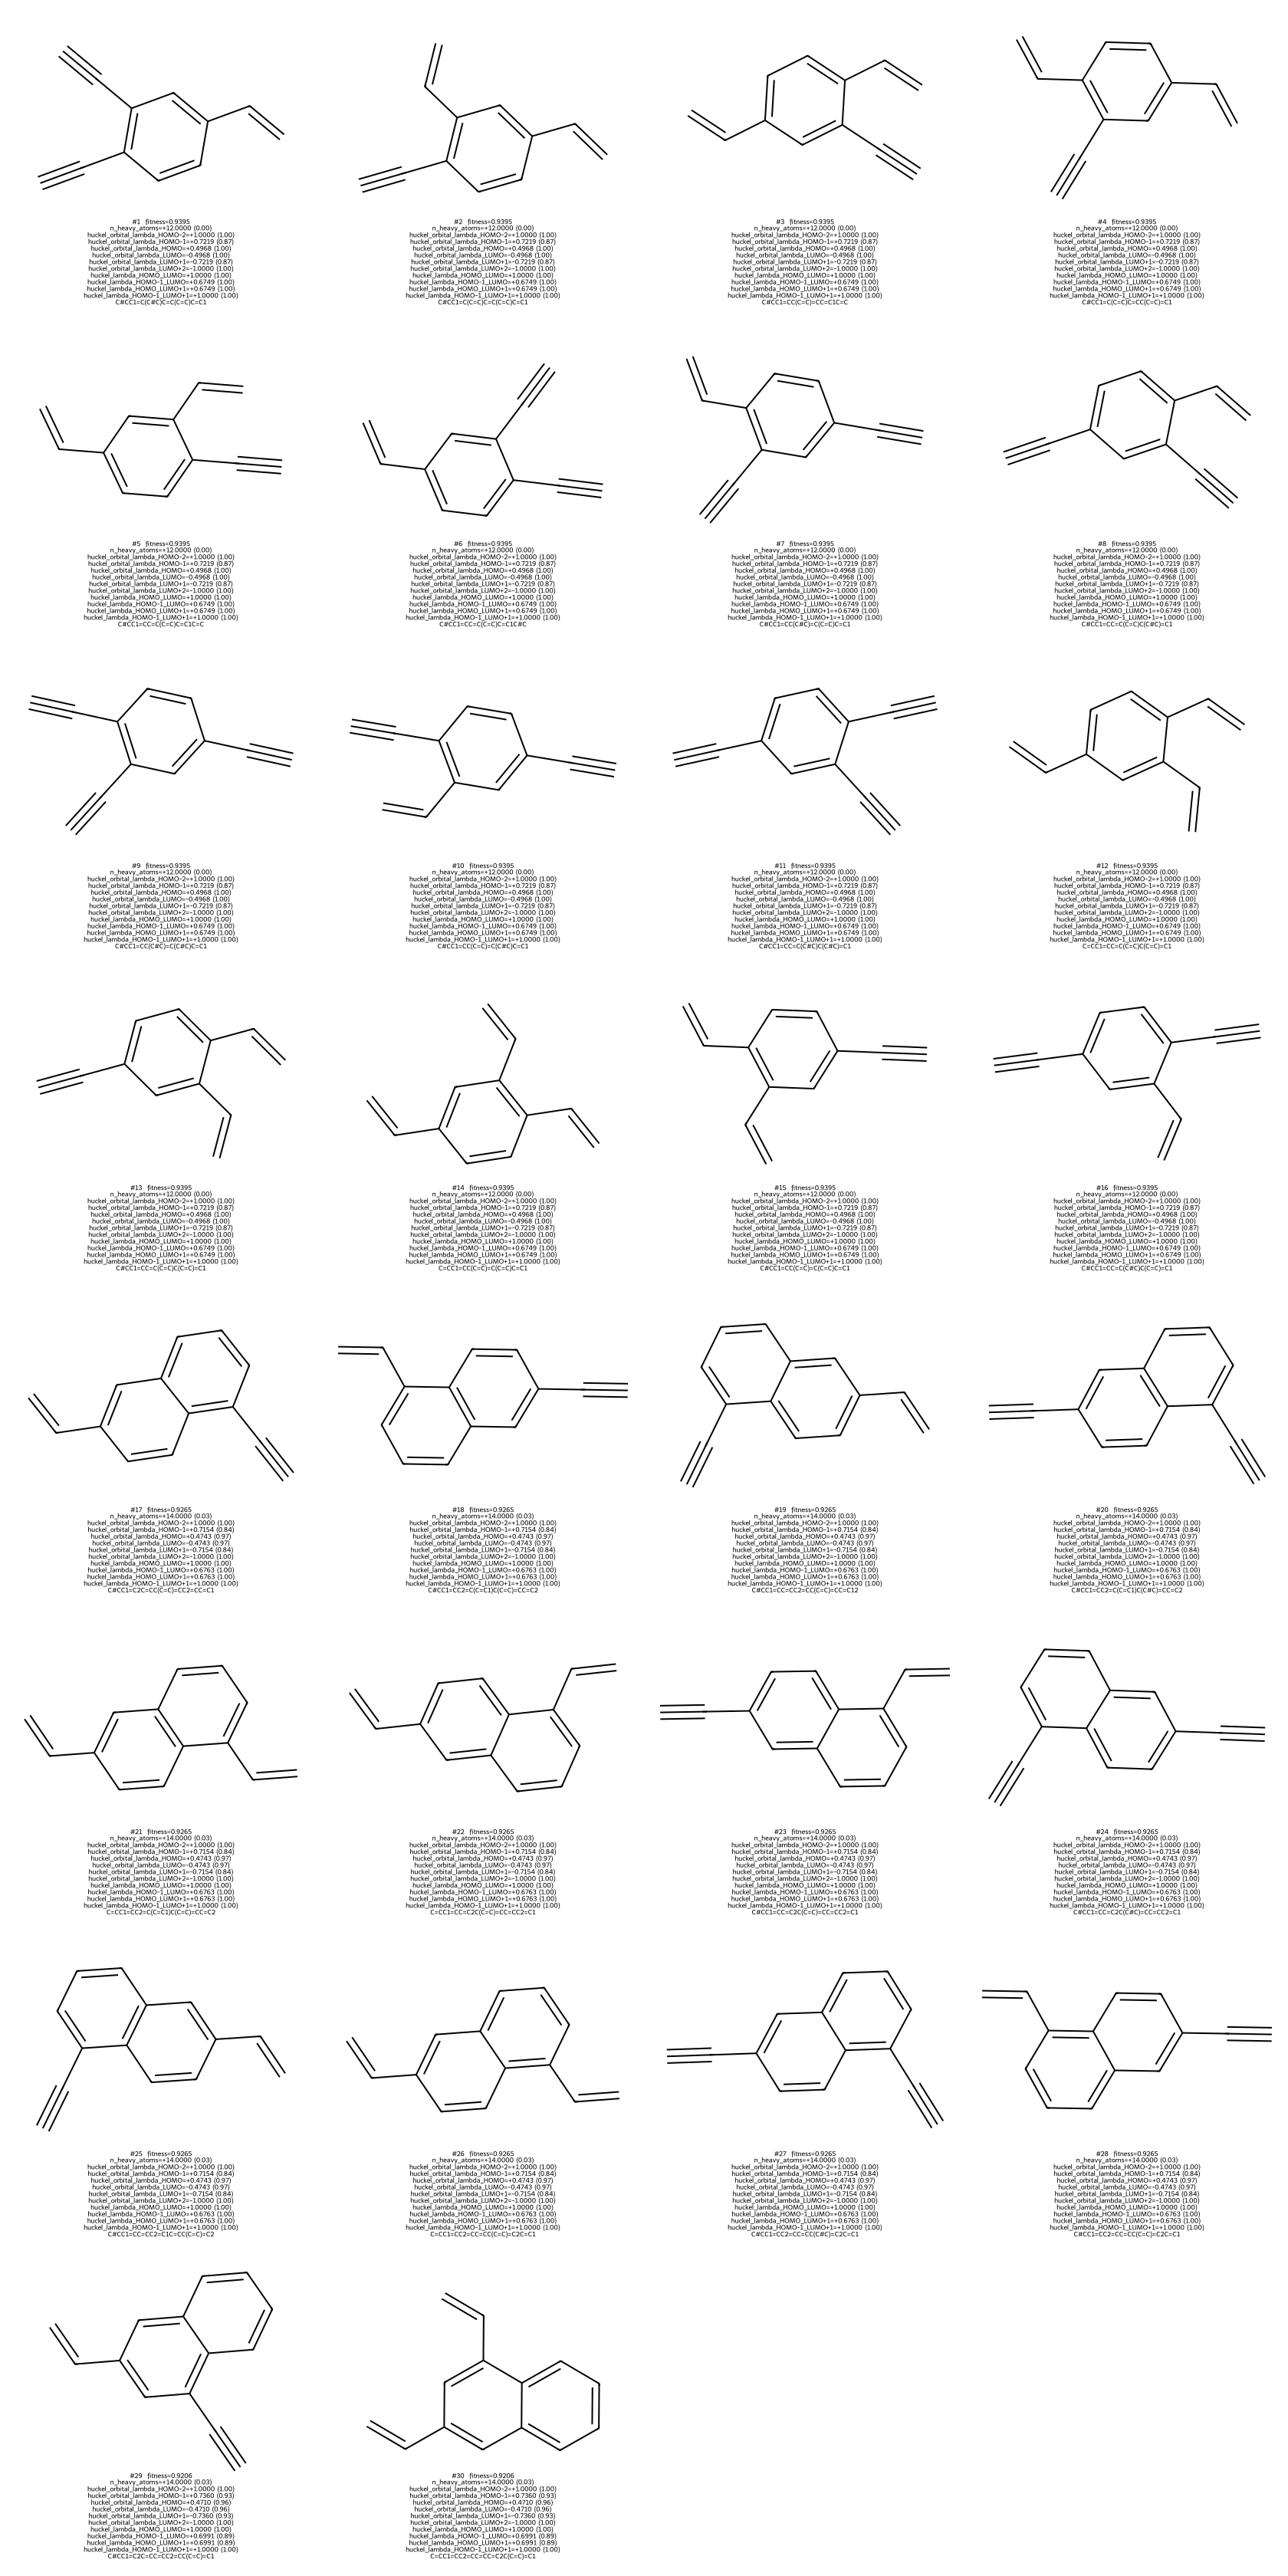

In [38]:
print(f"Générations effectuées : {evo_mol.nb_generations}")
print(f"Molécules uniques vues : {len(best_seen)}")
print(f"Agrégation : {AGGREGATION}")

goal_names = [name for name, *_ in fitness_goals]
col_width  = 26

header_cols = "  ".join(f"{n + ' (score)':>{col_width}}" for n in goal_names)
print(f"\nTop {TOP_N} molécules :")
print(f"{'Rang':<5} {'Fitness':>8}  {header_cols}  SMILES")
print("-" * (5 + 10 + (col_width + 2) * len(goal_names) + 50))

top_items = sorted(best_seen.values(), key=lambda x: x[0], reverse=True)[:TOP_N]
for rank, (fitness, mol) in enumerate(top_items, start=1):
    smiles      = mol.get_representation(MolecularGraph).canonical_smiles
    detail_cols = "  ".join(f"{f'{v:+.4f} ({s:.2f})':>{col_width}}" for _, v, s in ff.goal_scores(mol, fitness_goals))
    print(f"{rank:<5} {fitness:>8.4f}  {detail_cols}  {smiles}")

# ── Grille des TOP_N molécules ──────────────────────────────────────────────
_mols, _legends = [], []
for rank, (fitness, mol) in enumerate(top_items, start=1):
    smiles = mol.get_representation(MolecularGraph).canonical_smiles
    rdmol  = MolFromSmiles(smiles)
    if rdmol is None:
        continue
    _mols.append(rdmol)
    legend = f"#{rank}  fitness={fitness:.4f}"
    for name, val, score in ff.goal_scores(mol, fitness_goals):
        legend += f"\n{name}={val:+.4f} ({score:.2f})"
    legend += f"\n{smiles}"
    _legends.append(legend)

if _mols:
    # subImgSize large + legendFraction élevé : par défaut RDKit ne réserve que 10% de la
    # hauteur à la légende, illisible avec plusieurs lignes (fitness + un score par objectif).
    # drawOptions explicite (pas des kwargs nus) : dans un vrai notebook, IPythonConsole de
    # RDKit injecte son propre drawOptions et ignore sinon legendFontSize/legendFraction.
    _legend_opts = Draw.rdMolDraw2D.MolDrawOptions()
    _legend_opts.legendFontSize = 18
    _legend_opts.legendFraction = 0.30
    display(Draw.MolsToGridImage(_mols, molsPerRow=min(4, len(_mols)), subImgSize=(420, 420),
                                 legends=_legends, returnPNG=False, drawOptions=_legend_opts))

## 7. Évolution de la population sur les courbes

Chaque point = une molécule de la population (x = valeur brute, y = score de la courbe).
Couleur = génération (foncé = début, clair = fin). Le curseur montre une génération à la fois.

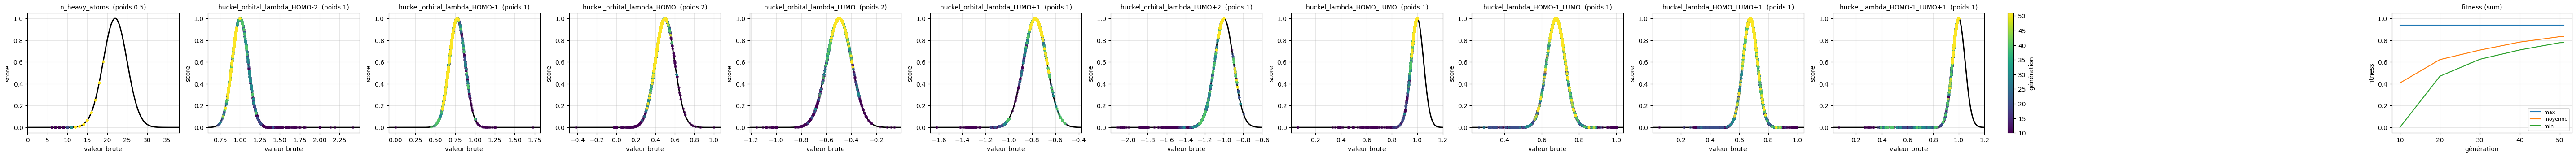

In [39]:
_gens = sorted(history)
if not _gens:
    raise RuntimeError("Aucun historique : lancer la recherche d'abord (§ 5).")

def _range_with_data(name, curve):
    lo, hi = CURVE_RANGES.get(name) or ff.auto_range(curve)
    vals = [v for g in _gens for v in history[g][name] if math.isfinite(v)]
    if vals:
        pad = 0.05 * ((max(vals) - min(vals)) or 1.0)
        lo, hi = min(lo, min(vals) - pad), max(hi, max(vals) + pad)
    return lo, hi

_ranges = {name: _range_with_data(name, curve) for name, curve, _ in fitness_goals}
_norm   = mcolors.Normalize(vmin=_gens[0], vmax=_gens[-1] if _gens[-1] > _gens[0] else _gens[0] + 1)
_cmap   = cm.viridis

# ── Vue d'ensemble : toutes les générations enregistrées ────────────────────
n = len(fitness_goals)
fig, axes = plt.subplots(1, n + 1, figsize=(4.8 * (n + 1), 3.6), squeeze=False)
axes = axes[0]
ff.plot_curves(fitness_goals, _ranges, axes=axes[:n])
for ax, (name, curve, _) in zip(axes[:n], fitness_goals):
    for g in _gens:
        vals = [v for v in history[g][name] if math.isfinite(v)]
        ax.scatter(vals, [curve(v) for v in vals], s=10, alpha=0.5, color=_cmap(_norm(g)), zorder=3)
# fitness de la population au fil des générations
ax = axes[n]
ax.plot(_gens, [max(history[g]["fitness"]) for g in _gens], label="max")
ax.plot(_gens, [sum(history[g]["fitness"]) / len(history[g]["fitness"]) for g in _gens], label="moyenne")
ax.plot(_gens, [min(history[g]["fitness"]) for g in _gens], label="min")
ax.set_ylim(-0.05, 1.05); ax.set_xlabel("génération"); ax.set_ylabel("fitness")
ax.set_title(f"fitness ({AGGREGATION})", fontsize=10); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.colorbar(cm.ScalarMappable(norm=_norm, cmap=_cmap), ax=list(axes[:n]), label="génération", pad=0.01)
plt.show()

# ── Une génération à la fois ────────────────────────────────────────────────
gen_slider = widgets.SelectionSlider(options=_gens, value=_gens[-1], description="génération",
                                     continuous_update=False, layout=widgets.Layout(width="600px"))
gen_plot = widgets.Image(format="png")

def _show_generation(*_):
    g = gen_slider.value
    fig, _ = ff.plot_curves(fitness_goals, _ranges, points=history[g])
    fit = history[g]["fitness"]
    fig.suptitle(f"Génération {g}  —  {len(fit)} molécules, fitness max {max(fit):.4f}, "
                 f"moyenne {sum(fit) / len(fit):.4f}", y=1.04)
    gen_plot.value = _fig_png(fig)

gen_slider.observe(_show_generation, names="value")
_show_generation()
display(widgets.VBox([gen_slider, gen_plot]))

## 8. Résumé et trajectoire

Même tableau et mêmes tracés que `search_parallel.ipynb` (meilleure fitness et taille moyenne en fonction du temps
et des générations), un point tous les `HISTORIQUE_TOUTES` générations.

course     générations  candidats/s  évaluations  rejets mémoire  meilleure fitness  fitness moyenne  atomes moyens  molécules distinctes
-----------------------------------------------------------------------------------------------------------------------------------------
recherche           51         3663      1153818         1751443             0.9395           0.8344           15.6                   403


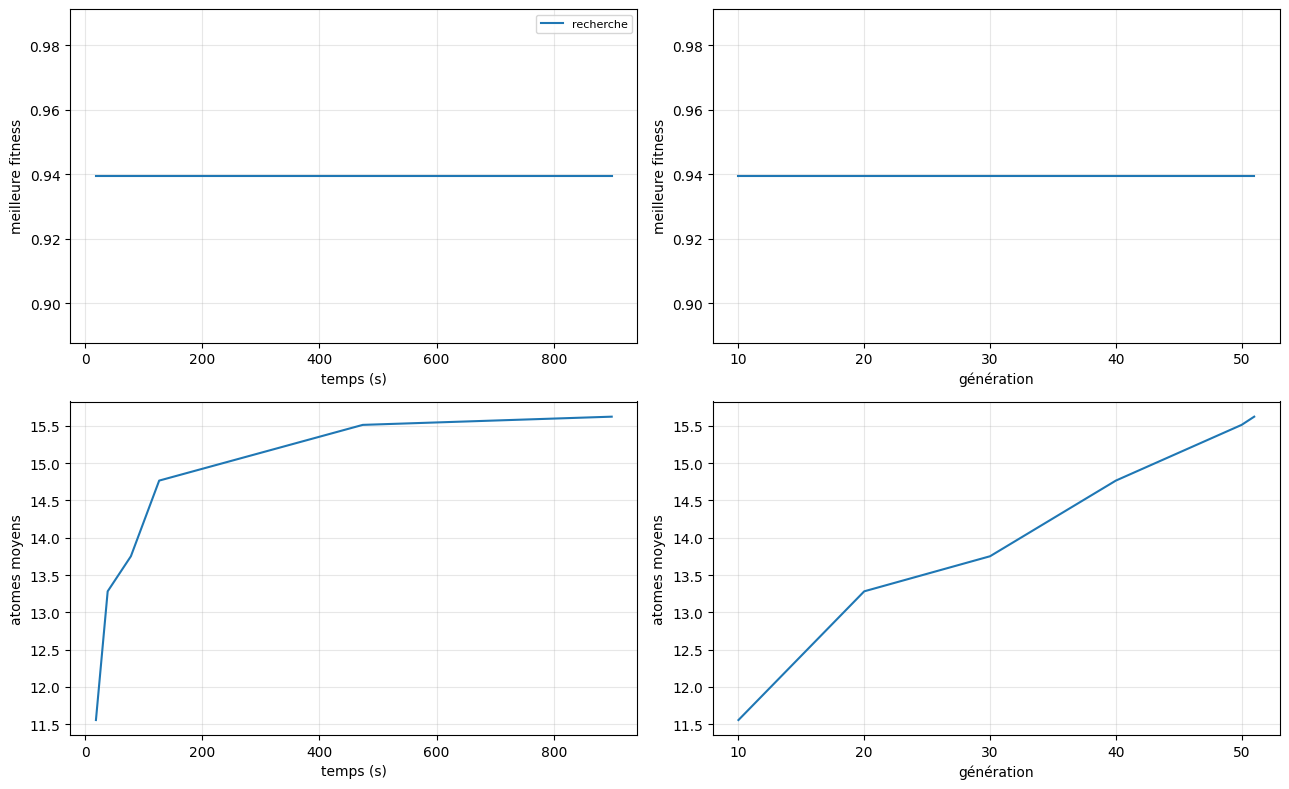

In [40]:
print(ps.summary_table(results))
fig = ps.plot_trajectories(results)
plt.show()